# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the untuned `SCRATCH_HYPERPARAMS`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: off
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = SCRATCH_HYPERPARAMS

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 947 | Val: 229 | Test: 567


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.0698 acc 0.517 | val loss 1.1567 acc 0.459 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 0.9862 acc 0.589 | val loss 0.8883 acc 0.624 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.8458 acc 0.661 | val loss 0.8113 acc 0.633 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.7897 acc 0.665 | val loss 0.8493 acc 0.624


...

[ResNet-18 (scratch)] Epoch  11/100 | LR: 1.00e-04 | train loss 0.4234 acc 0.827 | val loss 0.8026 acc 0.751


[ResNet-18 (scratch)] Epoch  12/100 | LR: 1.00e-04 | train loss 0.2951 acc 0.893 | val loss 1.1427 acc 0.668


[ResNet-18 (scratch)] Epoch  13/100 | LR: 1.00e-04 | train loss 0.3037 acc 0.890 | val loss 0.9938 acc 0.721


[ResNet-18 (scratch)] Epoch  14/100 | LR: 1.00e-04 | train loss 0.2361 acc 0.919 | val loss 1.1940 acc 0.681


[ResNet-18 (scratch)] Epoch  15/100 | LR: 1.00e-05 | train loss 0.2856 acc 0.888 | val loss 0.9773 acc 0.747

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 15.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.6907)


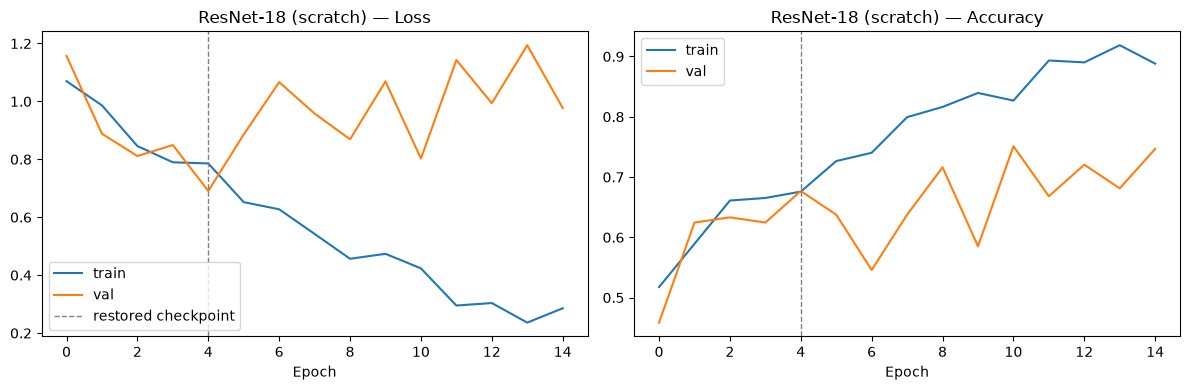

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.776


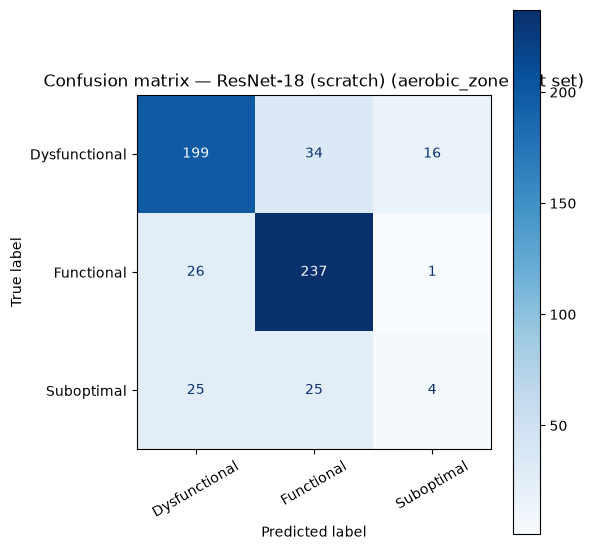

               precision    recall  f1-score   support

Dysfunctional      0.796     0.799     0.798       249
   Functional      0.801     0.898     0.846       264
   Suboptimal      0.190     0.074     0.107        54

     accuracy                          0.776       567
    macro avg      0.596     0.590     0.584       567
 weighted avg      0.741     0.776     0.755       567



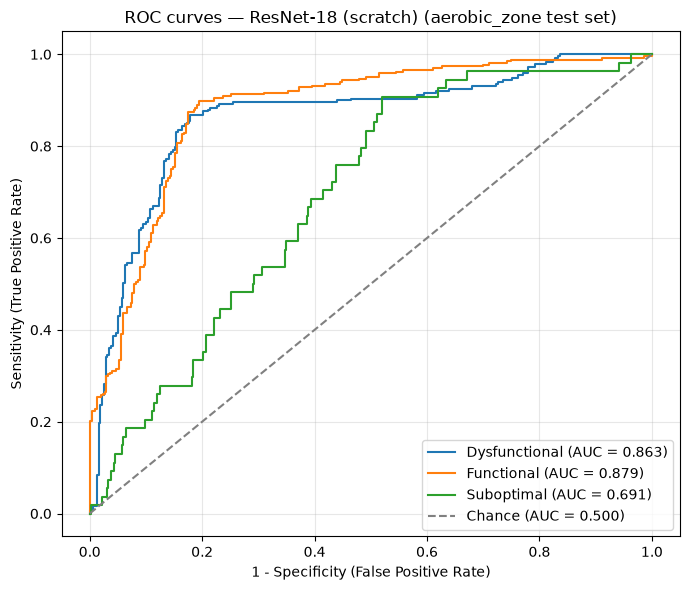

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.863
  Functional     : 0.879
  Suboptimal     : 0.691

Mean AUC (over 3/3 classes with test examples): 0.811


(np.float64(0.7760141093474426),
 {'Dysfunctional': 0.8626581798893689,
  'Functional': 0.8786378637863786,
  'Suboptimal': 0.6909248429716266})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_noaug/results_aerobic_zone_resnet18_scratch_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_noaug/aerobic_zone_resnet18_scratch_chronological.pt
